In [1]:
!pip install -q tensorflow-datasets
!pip install -U importlib-resources tensorflow-datasets

In [2]:
import tensorflow as tf
import tensorflow_datasets as tfds
import matplotlib.pyplot as plt
import numpy as np

print("Version TensorFlow :", tf.__version__)

Version TensorFlow : 2.21.0


In [3]:
(train_ds, val_ds, test_ds), metadata = tfds.load(
    "tf_flowers",
    split=[
        "train[:80%]",
        "train[80%:90%]",
        "train[90%:]"
    ],
    with_info=True,
    as_supervised=True
)

class_names = metadata.features["label"].names

print("Dataset téléchargé avec succès !")
print("Nombre de classes :", metadata.features["label"].num_classes)
print("Nombre d'images :", metadata.splits["train"].num_examples)

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Generating splits...:   0%|          | 0/1 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/tf_flowers/incomplete.W78W8Z_3.0.1/tf_flowers-train.tfrecord-[0-9][0-9][0-…

Dataset tf_flowers downloaded and prepared to /root/tensorflow_datasets/tf_flowers/3.0.1. Subsequent calls will reuse this data.
Dataset téléchargé avec succès !
Nombre de classes : 5
Nombre d'images : 3670


In [4]:
from collections import Counter


# Charger toutes les images originales pour l'analyse
# On utilise un dataset séparé afin de ne pas modifier
# les données utilisées pour l'entraînement.
ds_all = tfds.load(
    "tf_flowers",
    split="train",
    as_supervised=True
)

# Compter le nombre total d'images et les images par classe
class_counts = Counter()

for image, label in tfds.as_numpy(ds_all):
    class_counts[int(label)] += 1

total_images = sum(class_counts.values())
num_classes = len(class_names)

print("===== ANALYSE QUANTITATIVE =====")
print("Nombre total d'images :", total_images)
print("Nombre de classes :", num_classes)

print("\nNombre d'images par classe :")
for i, name in enumerate(class_names):
    print(f"{name:15s} : {class_counts[i]} images")

===== ANALYSE QUANTITATIVE =====
Nombre total d'images : 3670
Nombre de classes : 5

Nombre d'images par classe :
dandelion       : 898 images
daisy           : 633 images
tulips          : 799 images
sunflowers      : 699 images
roses           : 641 images


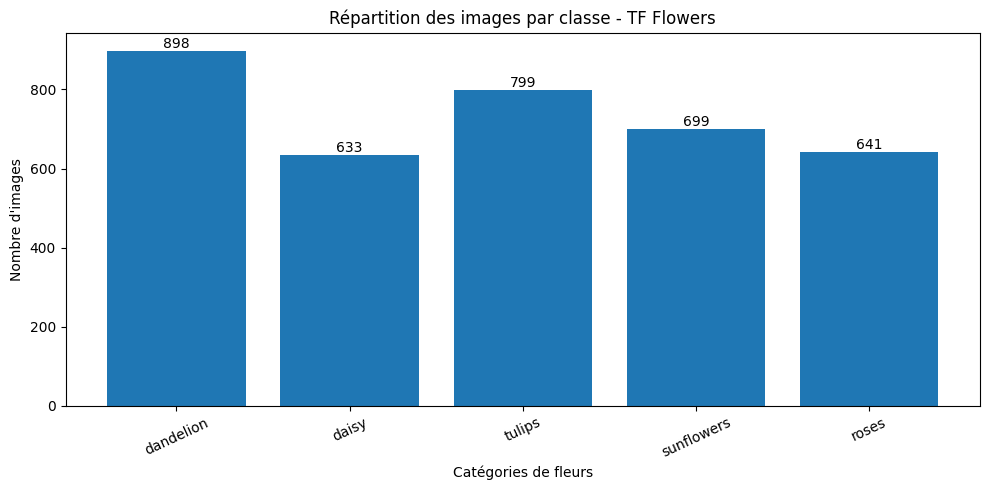

In [5]:
# Préparer les données pour le graphique
counts = [class_counts[i] for i in range(num_classes)]

plt.figure(figsize=(10, 5))

bars = plt.bar(class_names, counts)

plt.title("Répartition des images par classe - TF Flowers")
plt.xlabel("Catégories de fleurs")
plt.ylabel("Nombre d'images")
plt.xticks(rotation=25)

# Afficher le nombre d'images au-dessus de chaque barre
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        str(int(height)),
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

In [6]:
# Analyser les dimensions et les propriétés des images
image_shapes = Counter()
image_dtypes = Counter()
image_channels = Counter()

min_height, max_height = float("inf"), 0
min_width, max_width = float("inf"), 0

for image, label in tfds.as_numpy(ds_all):
    height, width, channels = image.shape

    # Compter les dimensions rencontrées
    image_shapes[(height, width)] += 1
    image_dtypes[str(image.dtype)] += 1
    image_channels[channels] += 1

    # Rechercher les dimensions minimales et maximales
    min_height = min(min_height, height)
    max_height = max(max_height, height)
    min_width = min(min_width, width)
    max_width = max(max_width, width)

print("===== DIMENSIONS ET FORMAT =====")
print("Dimensions les plus fréquentes :")
for shape, count in image_shapes.most_common(10):
    print(f"{shape[1]} x {shape[0]} : {count} images")

print("\nHauteur minimale :", min_height)
print("Hauteur maximale :", max_height)
print("Largeur minimale :", min_width)
print("Largeur maximale :", max_width)

print("\nTypes de données :", image_dtypes)
print("Nombre de canaux :", image_channels)

===== DIMENSIONS ET FORMAT =====
Dimensions les plus fréquentes :
500 x 333 : 635 images
320 x 240 : 618 images
320 x 213 : 331 images
240 x 240 : 208 images
180 x 240 : 155 images
500 x 375 : 132 images
500 x 332 : 120 images
159 x 240 : 80 images
500 x 334 : 71 images
500 x 331 : 55 images

Hauteur minimale : 159
Hauteur maximale : 442
Largeur minimale : 143
Largeur maximale : 1024

Types de données : Counter({'uint8': 3670})
Nombre de canaux : Counter({3: 3670})


In [7]:
# Paramètres du prétraitement
IMG_SIZE = (180, 180)
BATCH_SIZE = 32
NUM_CLASSES = 5

# Fonction de prétraitement des images
def preprocess(image, label):
    # Redimensionner toutes les images à la même résolution
    image = tf.image.resize(image, IMG_SIZE)

    # Convertir les pixels de [0, 255] vers [0, 1]
    image = tf.cast(image, tf.float32) / 255.0

    # Conserver l'étiquette entière de la classe
    return image, label

# Appliquer le prétraitement aux trois ensembles
train_ds = (
    train_ds
    .map(preprocess, num_parallel_calls=tf.data.AUTOTUNE)
    .shuffle(1000)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

val_ds = (
    val_ds
    .map(preprocess, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

test_ds = (
    test_ds
    .map(preprocess, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

print("Prétraitement terminé.")

Prétraitement terminé.


In [8]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.15),
    tf.keras.layers.RandomZoom(0.15),
    tf.keras.layers.RandomTranslation(
        height_factor=0.1,
        width_factor=0.1
    ),
], name="data_augmentation")

In [11]:
from tensorflow.keras import layers, models

cnn_ameliore = models.Sequential([
    layers.Input(shape=(180, 180, 3)),

    # Diversification des images
    data_augmentation,

    # Extraction des caractéristiques
    layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.20),

    layers.Conv2D(128, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.30),

    # Classification
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.40),
    layers.Dense(5, activation="softmax")
])

cnn_ameliore.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

cnn_ameliore.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 180, 180, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 90, 90, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 90, 90, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 45, 45, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 45, 45, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 45, 45, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 22, 22, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 22, 22, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,405 (431.27 KB)

 Trainable params: 110,405 (431.27 KB)

 Non-trainable params: 0 (0.00 B)

In [12]:
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

# Modèle pré-entraîné, sans sa couche de classification d'origine
base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(180, 180, 3)
)

# Geler les poids pré-entraînés au début
base_model.trainable = False

/tmp/ipykernel_888/4211869835.py:5: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base_model = MobileNetV2(


In [13]:
inputs = layers.Input(shape=(180, 180, 3))

x = data_augmentation(inputs)

# Passage de [0, 1] à [0, 255]
x = layers.Rescaling(255.0)(x)

# Prétraitement spécifique à MobileNetV2
x = layers.Lambda(preprocess_input)(x)

# Extraction des caractéristiques pré-apprises
x = base_model(x, training=False)

# Classification des cinq fleurs
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.30)(x)
x = layers.Dense(128, activation="relu")(x)
x = layers.Dropout(0.30)(x)
outputs = layers.Dense(5, activation="softmax")(x)

model_transfer = models.Model(inputs, outputs)

model_transfer.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model_transfer.summary()

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda (Lambda)                 │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 6, 6, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,597 (9.24 MB)

 Trainable params: 164,613 (643.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [15]:
early_stopping_tl = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=4,
    restore_best_weights=True
)

history_transfer = model_transfer.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=[early_stopping_tl]
)


Epoch 1/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 5s 50ms/step - accuracy: 0.8699 - loss: 0.3521 - val_accuracy: 0.8965 - val_loss: 0.3148
Epoch 2/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 5s 48ms/step - accuracy: 0.8685 - loss: 0.3565 - val_accuracy: 0.8937 - val_loss: 0.2816
Epoch 3/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 5s 48ms/step - accuracy: 0.8726 - loss: 0.3400 - val_accuracy: 0.9183 - val_loss: 0.2690
Epoch 4/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 5s 47ms/step - accuracy: 0.8832 - loss: 0.3142 - val_accuracy: 0.9155 - val_loss: 0.2906
Epoch 5/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 5s 47ms/step - accuracy: 0.8770 - loss: 0.3279 - val_accuracy: 0.8910 - val_loss: 0.3084
Epoch 6/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 5s 47ms/step - accuracy: 0.8753 - loss: 0.3322 - val_accuracy: 0.9237 - val_loss: 0.2828
Epoch 7/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 5s 47ms/step - accuracy: 0.8920 - loss: 0.2966 - val_accuracy: 0.9101 - val_loss: 0.2737


In [17]:
model_transfer.save("model_transfer.keras")

In [18]:
from google.colab import files

files.download("model_transfer.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>